# Visualize Dynamic Regime Data

Set `DATA_DIR` to a trajectory directory created by `generate_dynamic_regime_trajectories.py` or to a resampled window directory created by `resample_time_varying_bifurcation_windows.py`.

The plots color time by normalized `phi`: negative values are before the transition marker, `phi=0` is the marked crossing, and positive values are after it.

In [7]:
from pathlib import Path
import json

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from mpl_toolkits.mplot3d.art3d import Line3DCollection

plt.rcParams.update(
    {
        "figure.dpi": 120,
        "axes.grid": True,
        "grid.alpha": 0.3,
    }
)

# Change this to your generated trajectory directory or resampled window directory.
DATA_DIR = Path(
    # "justtesting\halvorsen_209to14_1kstpes"
    "generated_dynamic_regime_trajectories"
)

metadata_path = DATA_DIR / "metadata.json"
with open(metadata_path, "r", encoding="utf-8") as f:
    metadata = json.load(f)

metadata.get("description", "")

'Dynamic regime-change trajectories with known normalized phi_t. No training windows are sampled by this script; use resample_time_varying_bifurcation_windows.py afterwards.'

In [8]:
def load_if_exists(name):
    path = DATA_DIR / name
    return np.load(path, allow_pickle=True) if path.exists() else None


trajectories = load_if_exists("trajectories.npy")
trajectory_phi = load_if_exists("trajectory_phi.npy")
trajectory_phi_raw = load_if_exists("trajectory_phi_raw.npy")
trajectory_regime_names = load_if_exists("trajectory_regime_names.npy")

context = load_if_exists("context.npy")
data = load_if_exists("data.npy")
context_phi = load_if_exists("context_phi.npy")
phi = load_if_exists("phi.npy")
test = load_if_exists("test.npy")
test_phi = load_if_exists("test_phi.npy")
window_regime_names = load_if_exists("window_regime_names.npy")
window_sampling_modes = load_if_exists("window_sampling_modes.npy")

print("DATA_DIR:", DATA_DIR.resolve())
for name, arr in [
    ("trajectories", trajectories),
    ("trajectory_phi", trajectory_phi),
    ("context", context),
    ("data", data),
    ("phi", phi),
    ("test", test),
    ("test_phi", test_phi),
]:
    if arr is not None:
        print(f"{name:16s} {arr.shape}")

print("\nRegimes:")
for i, regime in enumerate(metadata.get("regimes", [])):
    print(
        f"{i:2d}: {regime['name']} | {regime.get('transition_type', 'n/a')} | {regime['parameter']} {regime['start']} -> {regime['end']} | boundary {regime['boundary']}"
    )

DATA_DIR: C:\Users\koray\OneDrive\Dokumente\Studium\Master\Heidelberg\Master_Thesis\generate_trainingdata\time_varying_bifurcation_data\generated_dynamic_regime_trajectories
trajectories     (72, 100000, 3)
trajectory_phi   (72, 100000, 1)

Regimes:
 0: rossler_c_periodic_to_chaotic | periodic_to_chaotic | c 3.5 -> 5.7 | boundary 4.2
 1: rossler_c_chaotic_to_periodic | chaotic_to_periodic | c 5.7 -> 3.5 | boundary 4.2
 2: duffing_gamma_periodic_to_chaotic | periodic_to_chaotic | gamma 0.2 -> 0.38 | boundary 0.29
 3: duffing_gamma_chaotic_to_periodic | chaotic_to_periodic | gamma 0.38 -> 0.2 | boundary 0.29
 4: forced_vdp_amp_periodic_to_periodic | periodic_to_periodic | forcing_amplitude 0.05 -> 0.45 | boundary 0.25
 5: forced_vdp_amp_periodic_to_mixed | periodic_to_chaotic | forcing_amplitude 0.2 -> 1.2 | boundary 0.75
 6: lorenz_rho_chaotic_attractor_change | chaotic_to_chaotic | rho 28.0 -> 100.0 | boundary 60.0
 7: lorenz_rho_high_to_classic_chaos | chaotic_to_chaotic | rho 100.0 -

## Helper Functions

In [9]:
def crossing_index(phi_series):
    flat = np.asarray(phi_series).reshape(-1)
    changes = np.flatnonzero(np.signbit(flat[:-1]) != np.signbit(flat[1:]))
    return int(changes[0] + 1) if changes.size else None


def regime_title(names, index):
    if names is None:
        return f"series {index}"
    return str(names[index])


def colored_3d_line(ax, xyz, color_values, cmap="coolwarm", linewidth=1.2):
    points = xyz.reshape(-1, 1, 3)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)
    lc = Line3DCollection(segments, cmap=cmap, linewidth=linewidth)
    lc.set_array(color_values[:-1])
    ax.add_collection3d(lc)
    ax.set_xlim(np.nanmin(xyz[:, 0]), np.nanmax(xyz[:, 0]))
    ax.set_ylim(np.nanmin(xyz[:, 1]), np.nanmax(xyz[:, 1]))
    ax.set_zlim(np.nanmin(xyz[:, 2]), np.nanmax(xyz[:, 2]))
    return lc


def colored_2d_line(ax, x, y, color_values, cmap="coolwarm", linewidth=1.0):
    points = np.column_stack([x, y]).reshape(-1, 1, 2)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)
    lc = LineCollection(segments, cmap=cmap, linewidth=linewidth)
    lc.set_array(color_values[:-1])
    ax.add_collection(lc)
    ax.set_xlim(x[0], x[-1])
    y_min, y_max = np.nanmin(y), np.nanmax(y)
    pad = 0.05 * max(y_max - y_min, 1e-8)
    ax.set_ylim(y_min - pad, y_max + pad)
    return lc


def pick_series_by_regime(names, regime_name=None, occurrence=0):
    if names is None or regime_name is None:
        return occurrence
    matches = np.flatnonzero(np.asarray(names).astype(str) == regime_name)
    if not len(matches):
        raise ValueError(f"No series/window for regime {regime_name!r}")
    return int(matches[min(occurrence, len(matches) - 1)])

## Whole Trajectory: 3D View

Color encodes normalized `phi`. Blue is before the transition marker, white is near `phi=0`, red is after it.

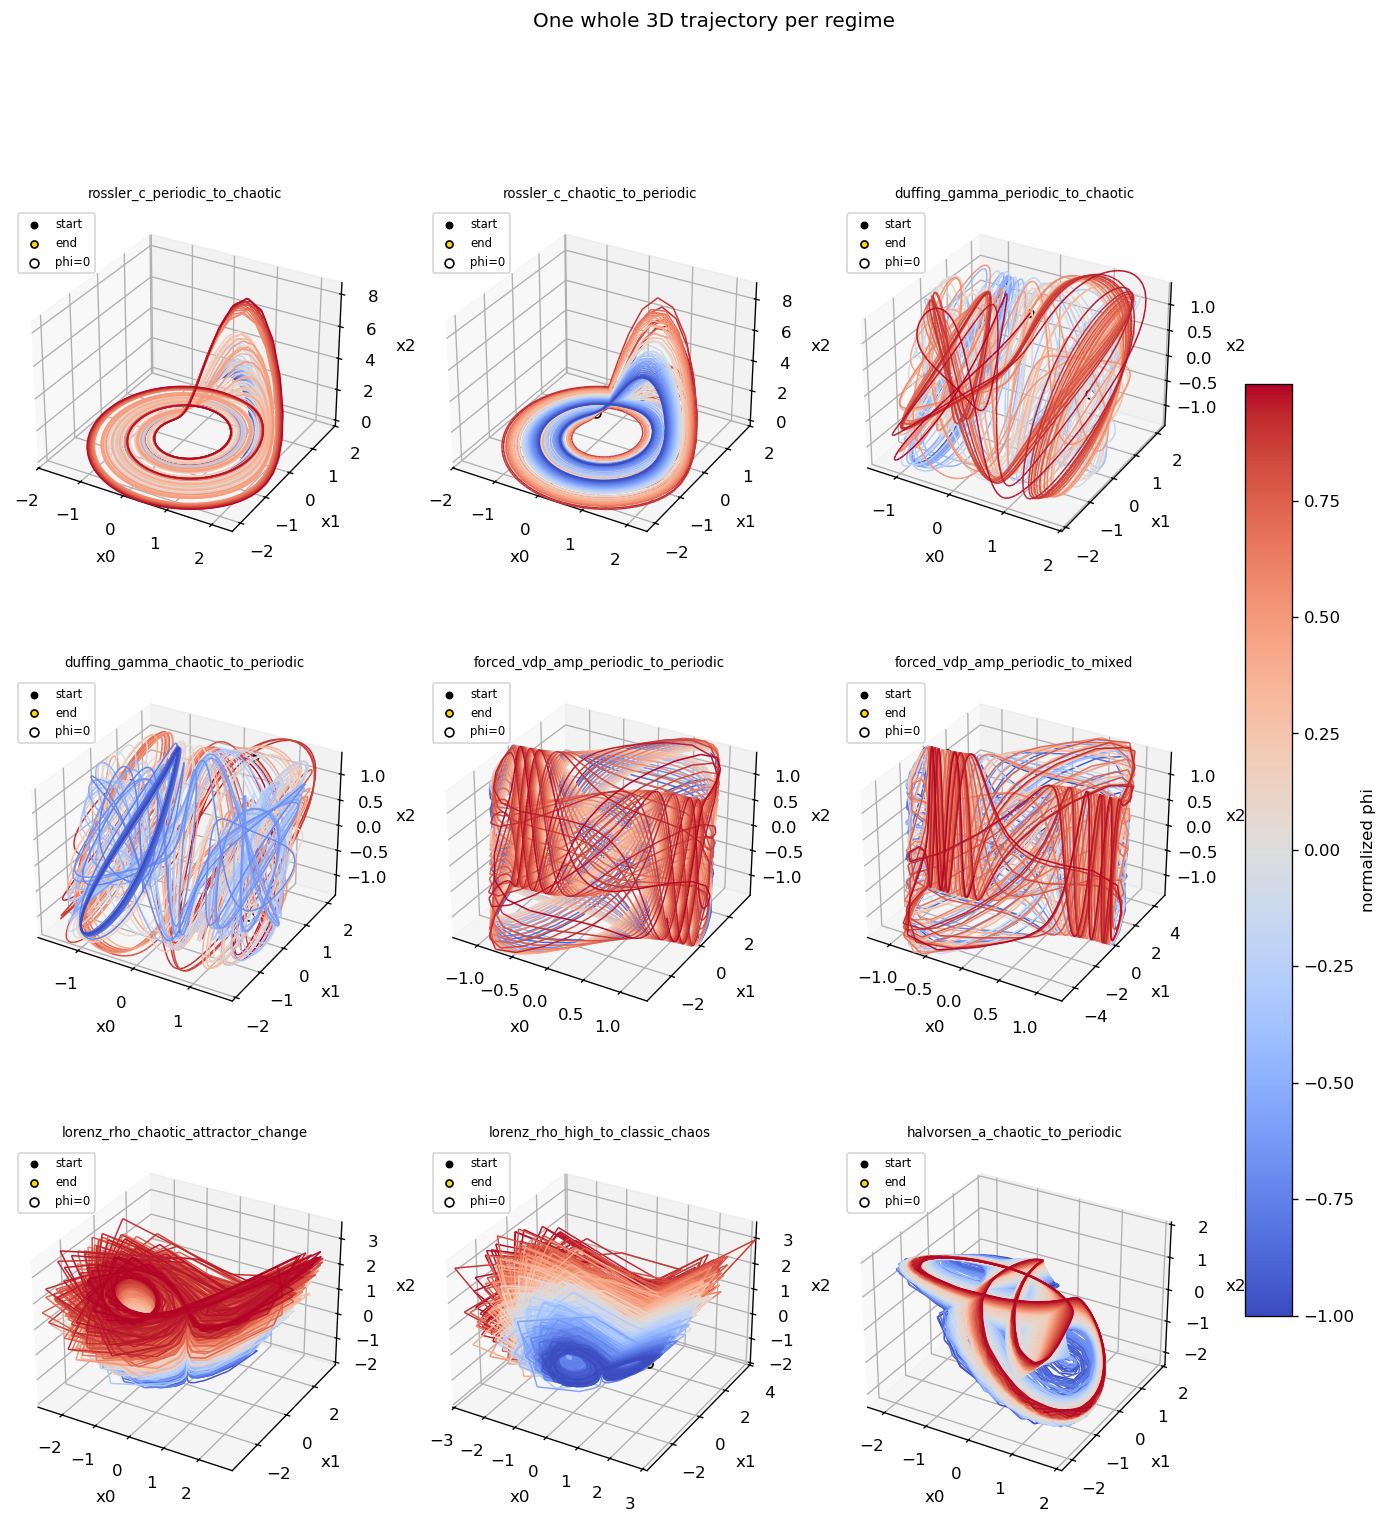

In [16]:
if trajectories is None:
    print(
        "No full trajectories found in DATA_DIR. Use a generator output directory, or rerun resampling with --copy-full-arrays."
    )
else:
    if trajectory_regime_names is None:
        series_indices = list(range(trajectories.shape[0]))
    else:
        unique_names = list(dict.fromkeys(trajectory_regime_names.astype(str)))
        series_indices = [
            pick_series_by_regime(trajectory_regime_names, name)
            for name in unique_names
        ]

    STRIDE = max(1, trajectories.shape[1] // 12000)
    n = len(series_indices)
    ncols = min(3, n)
    nrows = int(np.ceil(n / ncols))

    fig = plt.figure(figsize=(5.2 * ncols, 4.8 * nrows))
    axes = []
    last_lc = None

    for plot_pos, series_index in enumerate(series_indices, start=1):
        ax = fig.add_subplot(nrows, ncols, plot_pos, projection="3d")
        axes.append(ax)

        xyz = trajectories[series_index, ::STRIDE]
        p = trajectory_phi[series_index, ::STRIDE, 0]
        cidx = crossing_index(trajectory_phi[series_index, :, 0])

        last_lc = colored_3d_line(ax, xyz, p, linewidth=0.9)
        ax.scatter(xyz[0, 0], xyz[0, 1], xyz[0, 2], color="black", s=14, label="start")
        ax.scatter(
            xyz[-1, 0],
            xyz[-1, 1],
            xyz[-1, 2],
            color="gold",
            edgecolor="black",
            s=18,
            label="end",
        )

        if cidx is not None:
            cp = trajectories[series_index, cidx]
            ax.scatter(
                cp[0],
                cp[1],
                cp[2],
                color="white",
                edgecolor="black",
                s=28,
                label="phi=0",
            )

        ax.set_title(regime_title(trajectory_regime_names, series_index), fontsize=8)
        ax.set_xlabel("x0")
        ax.set_ylabel("x1")
        ax.set_zlabel("x2")
        ax.legend(loc="upper left", fontsize=7)

    if last_lc is not None:
        fig.colorbar(last_lc, ax=axes, pad=0.04, shrink=0.7, label="normalized phi")

    fig.suptitle("One whole 3D trajectory per regime", y=0.98)
    plt.show()

## Whole Trajectory: Dimensions Over Time

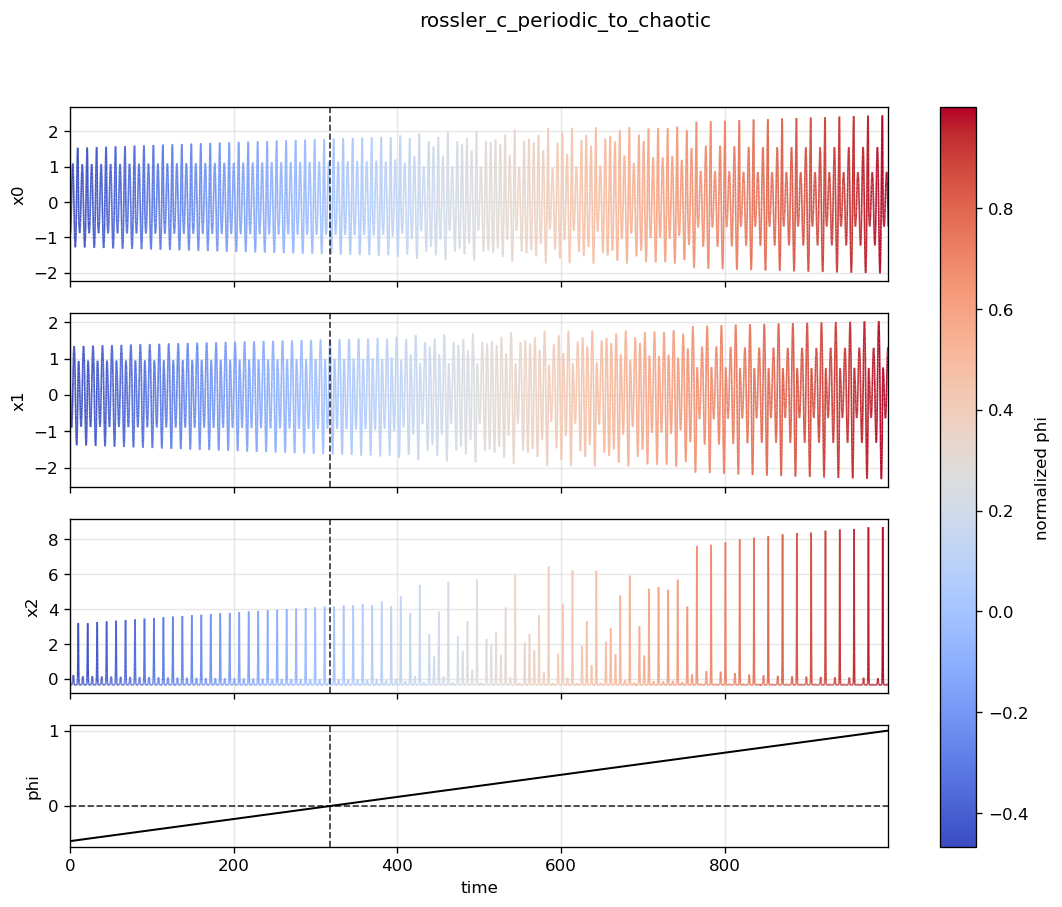

In [17]:
if trajectories is None:
    print("No full trajectories found in DATA_DIR.")
else:
    for idx in range(0, 1):
        SERIES_INDEX = idx
        STRIDE = max(1, trajectories.shape[1] // 20000)
        dt = metadata.get("args", {}).get("dt", 1.0)
        t = np.arange(trajectories.shape[1])[::STRIDE] * dt
        x = trajectories[SERIES_INDEX, ::STRIDE]
        p = trajectory_phi[SERIES_INDEX, ::STRIDE, 0]
        cidx = crossing_index(trajectory_phi[SERIES_INDEX, :, 0])
        t_cross = cidx * dt if cidx is not None else None

        fig, axes = plt.subplots(
            4,
            1,
            figsize=(11, 8),
            sharex=True,
            gridspec_kw={"height_ratios": [1, 1, 1, 0.7]},
        )
        last_lc = None
        for dim, ax in enumerate(axes[:3]):
            last_lc = colored_2d_line(ax, t, x[:, dim], p)
            ax.set_ylabel(f"x{dim}")
            if t_cross is not None:
                ax.axvline(
                    t_cross, color="black", linestyle="--", linewidth=1, alpha=0.8
                )
        axes[3].plot(t, p, color="black", linewidth=1.2)
        axes[3].axhline(0, color="black", linestyle="--", linewidth=1, alpha=0.8)
        if t_cross is not None:
            axes[3].axvline(
                t_cross, color="black", linestyle="--", linewidth=1, alpha=0.8
            )
        axes[3].set_ylabel("phi")
        axes[3].set_xlabel("time")
        fig.suptitle(regime_title(trajectory_regime_names, SERIES_INDEX))
        fig.colorbar(last_lc, ax=axes, label="normalized phi")
        plt.show()

## Overview By Regime

One representative trajectory per regime, projected to `(x0, x1)`.

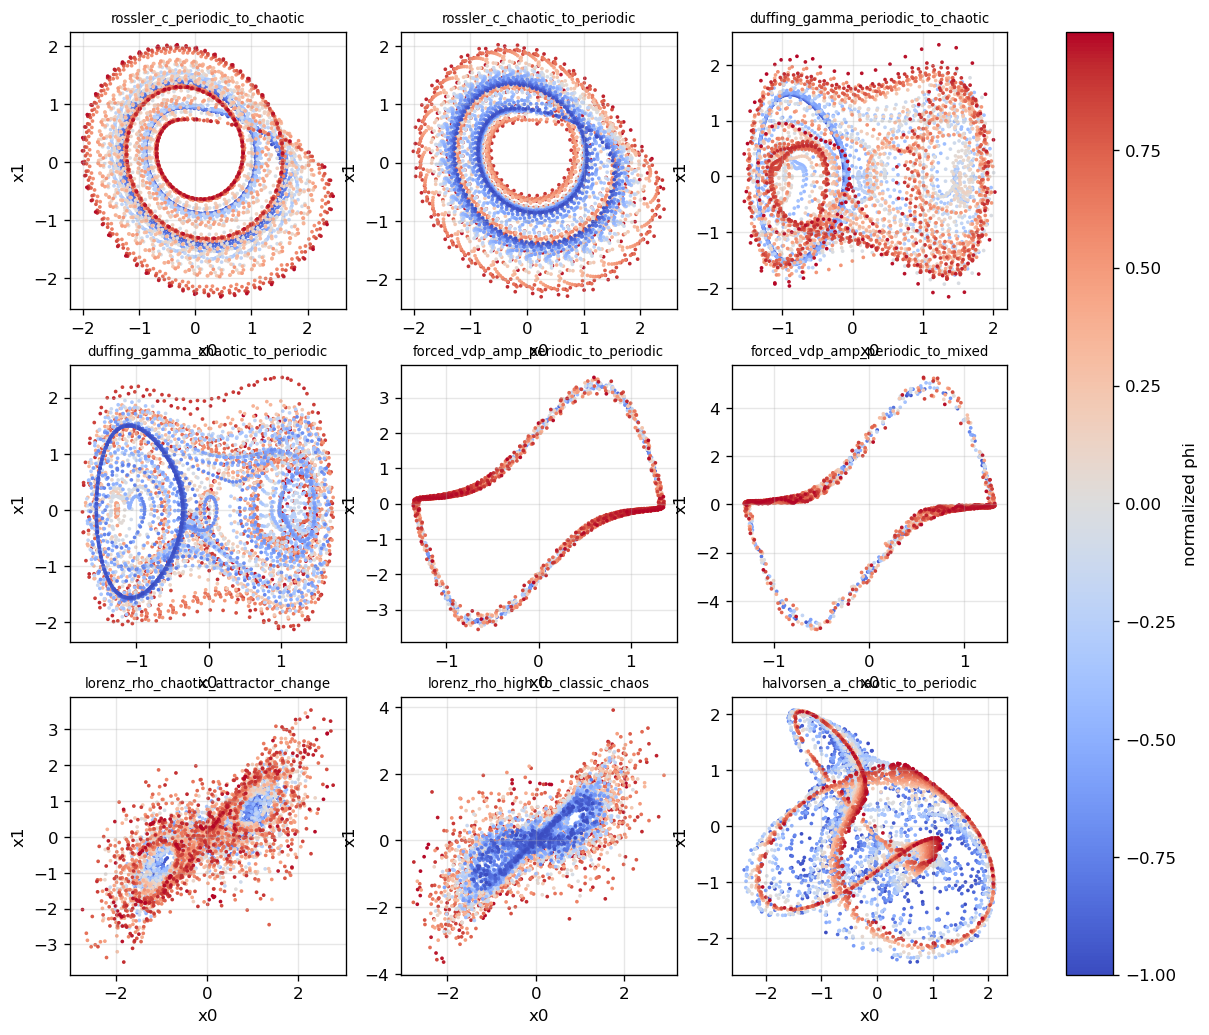

In [12]:
if trajectories is None or trajectory_regime_names is None:
    print("No full trajectory regime names found.")
else:
    unique_names = list(dict.fromkeys(trajectory_regime_names.astype(str)))
    n = len(unique_names)
    ncols = 3
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(4.2 * ncols, 3.4 * nrows), squeeze=False
    )
    for ax, name in zip(axes.ravel(), unique_names):
        idx = pick_series_by_regime(trajectory_regime_names, name)
        stride = max(1, trajectories.shape[1] // 5000)
        xy = trajectories[idx, ::stride, :2]
        p = trajectory_phi[idx, ::stride, 0]
        lc = colored_2d_line(ax, np.arange(len(xy)), xy[:, 0], p)
        ax.clear()
        sc = ax.scatter(xy[:, 0], xy[:, 1], c=p, s=1.5, cmap="coolwarm")
        ax.set_title(name, fontsize=8)
        ax.set_xlabel("x0")
        ax.set_ylabel("x1")
    for ax in axes.ravel()[n:]:
        ax.axis("off")
    fig.colorbar(sc, ax=axes.ravel().tolist(), label="normalized phi")
    plt.show()

## Window Diagnostics

Works when `DATA_DIR` points to a resampled window directory.

In [13]:
if context is None or data is None:
    print("No resampled context/data arrays found in DATA_DIR.")
else:
    WINDOW_INDEX = 0
    y = np.concatenate([context[:, WINDOW_INDEX], data[:, WINDOW_INDEX]], axis=0)
    p = np.concatenate(
        [context_phi[:, WINDOW_INDEX, 0], phi[:, WINDOW_INDEX, 0]], axis=0
    )
    t = np.arange(len(y))
    split = context.shape[0]
    cidx = crossing_index(p)
    title = f"window {WINDOW_INDEX}"
    if window_regime_names is not None:
        title += f" | {window_regime_names[WINDOW_INDEX]}"
    if window_sampling_modes is not None:
        title += f" | {window_sampling_modes[WINDOW_INDEX]}"

    fig, axes = plt.subplots(
        4,
        1,
        figsize=(11, 7.5),
        sharex=True,
        gridspec_kw={"height_ratios": [1, 1, 1, 0.7]},
    )
    last_lc = None
    for dim, ax in enumerate(axes[:3]):
        last_lc = colored_2d_line(ax, t, y[:, dim], p)
        ax.axvline(
            split,
            color="black",
            linewidth=1,
            alpha=0.6,
            label="context/data split" if dim == 0 else None,
        )
        if cidx is not None:
            ax.axvline(
                cidx,
                color="black",
                linestyle="--",
                linewidth=1,
                alpha=0.8,
                label="phi=0" if dim == 0 else None,
            )
        ax.set_ylabel(f"x{dim}")
    axes[0].legend(loc="upper right")
    axes[3].plot(t, p, color="black", linewidth=1.2)
    axes[3].axhline(0, color="black", linestyle="--", linewidth=1)
    axes[3].axvline(split, color="black", linewidth=1, alpha=0.6)
    if cidx is not None:
        axes[3].axvline(cidx, color="black", linestyle="--", linewidth=1, alpha=0.8)
    axes[3].set_ylabel("phi")
    axes[3].set_xlabel("window time index")
    fig.suptitle(title)
    fig.colorbar(last_lc, ax=axes, label="normalized phi")
    plt.show()

No resampled context/data arrays found in DATA_DIR.


## Are Windows Informative?

These histograms help detect nearly constant windows. Very low standard deviation means the model mostly sees fixed-point-like data.

In [14]:
if context is None or data is None:
    print("No resampled context/data arrays found in DATA_DIR.")
else:
    windows = np.concatenate([context, data], axis=0)  # T, S, D
    per_window_std = windows.std(axis=0).mean(axis=1)
    p_windows = np.concatenate([context_phi, phi], axis=0)[:, :, 0]
    min_abs_phi = np.min(np.abs(p_windows), axis=0)

    fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
    axes[0].hist(per_window_std, bins=40, color="steelblue", edgecolor="white")
    axes[0].set_title("Mean std per window")
    axes[0].set_xlabel("std")
    axes[0].set_ylabel("count")

    axes[1].hist(min_abs_phi, bins=40, color="darkorange", edgecolor="white")
    axes[1].set_title("Closest approach to phi=0")
    axes[1].set_xlabel("min |phi|")

    axes[2].scatter(min_abs_phi, per_window_std, s=8, alpha=0.5)
    axes[2].set_title("Window activity vs transition proximity")
    axes[2].set_xlabel("min |phi|")
    axes[2].set_ylabel("mean std")
    plt.show()

    print(
        "std quantiles:",
        np.quantile(per_window_std, [0, 0.05, 0.25, 0.5, 0.75, 0.95, 1.0]),
    )

No resampled context/data arrays found in DATA_DIR.


## Window Mode Counts

In [15]:
if window_sampling_modes is None:
    print("No window_sampling_modes.npy found.")
else:
    modes, counts = np.unique(window_sampling_modes.astype(str), return_counts=True)
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.bar(modes, counts, color="slategray")
    ax.set_title("Sampled window modes")
    ax.set_ylabel("count")
    plt.show()
    print(dict(zip(modes, counts)))

No window_sampling_modes.npy found.
